# Collaboration step 1, notebook 2: frozen encoders, heads, tuning without selection bias, the external test

Transfer learning by feature extraction: a pretrained encoder is kept **frozen**; only the head learns from the public labels. Everything follows [SUBSTANCE_PROTOCOL.md](../../SUBSTANCE_PROTOCOL.md),
written before any model was trained: nested grouped folds, selection without bias, the rule for keeping a complex head, the external test scored once.

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("../../helpers").resolve()))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 80); pd.set_option("display.max_columns", 30)
import data, substance
from cleaning import substance as rule_score, clean_text, is_padding, APPROVAL_ONLY
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
od, rh = data.public_pool()
od = od.reset_index(drop=True); rh = rh.reset_index(drop=True)
CS = substance.combos(od.group.to_numpy())
OUTER = {}
for o, i, tr, va, te in CS:
    OUTER[o] = (np.setdiff1d(np.arange(len(od)), te), te)
def guarded(original):
    c = clean_text(original)
    return len(c.split()) < 3 or bool(APPROVAL_ONLY.match(c)) or is_padding(c)

## 1. Embeddings (computed once per encoder, cached)

In [2]:
import time
EMB, VARIANTS = {}, ["emb", "emb+meta"]
texts_od, texts_rh = od.clean.tolist(), rh.clean.tolist()
M_od, M_rh = substance.meta(od.text.tolist(), texts_od), substance.meta(rh.text.tolist(), texts_rh)
for enc in substance.ENCODERS:
    t0 = time.time()
    E = substance.embed(enc, texts_od + texts_rh)
    EMB[enc] = (E[:len(od)], E[len(od):])
    print(f"{enc}: {E.shape}  ({time.time() - t0:.0f}s)")
def matrix(enc, variant, part):
    E = EMB[enc][0 if part == "od" else 1]
    if variant == "emb":
        return E
    M = M_od if part == "od" else M_rh
    return np.hstack([E, (M - M_od.mean(0)) / (M_od.std(0) + 1e-9)])   # standardised with OpenDev statistics only

MiniLM: (3964, 384)  (0s)
mpnet: (3964, 768)  (0s)
roberta: (3964, 768)  (0s)


## 2. Tuning on OpenDev: 3 encoders x 2 text variants x 3 head families (logistic 9 settings, forest 8, boosting 8)

Every configuration is scored on every (outer, inner) combination (5 x 4 = 20); nothing from RevHelper is used. This takes a while on CPU the first time; the result is cached.

In [3]:
embs = {(enc, v): matrix(enc, v, "od") for enc in substance.ENCODERS for v in VARIANTS}
t0 = time.time()
tuned, preds = substance.run_tuning(embs, od.y.to_numpy(), od.group.to_numpy(), RESULTS / "tuning.csv", workers=10)
print(len(tuned), "scored configurations x combinations;", f"{time.time() - t0:.0f}s")
st = json.load(open(RESULTS / "tuning.settings.json"))
tuned.groupby(["encoder", "variant", "family"]).auc.mean().unstack("family").round(3)

3000 scored configurations x combinations; 0s


family            boosting  forest  logistic
encoder variant                             
MiniLM  emb          0.677   0.688     0.676
        emb+meta     0.680   0.689     0.666
mpnet   emb          0.667   0.682     0.674
        emb+meta     0.667   0.683     0.666
roberta emb          0.701   0.702     0.686
        emb+meta     0.701   0.703     0.677

## 3. Selection without bias: which encoder, text variant and head family

For every (outer, inner) combination the configuration is chosen on the other three inner folds of the same outer fold and scored on the held-out one. The pooled predictions compare the options.

In [4]:
rows = []
for enc in substance.ENCODERS:
    for fam in ("logistic", "forest", "boosting"):
        sub = tuned[(tuned.encoder == enc) & (tuned.family == fam)]
        y, p, g, perfold, pick = substance.pooled_bias_free(sub, preds, od.y.to_numpy(), od.group.to_numpy(), CS)
        rows.append({"encoder": enc, "head": fam, "pooled AUC": substance.auc_scores(y, p)["AUC"], "folds": [round(v, 3) for v in perfold.values()]})
sel = pd.DataFrame(rows).sort_values("pooled AUC", ascending=False).reset_index(drop=True)
sel.round(3)

,encoder,head,pooled AUC,folds
0,roberta,forest,0.703,"[0.702, 0.72, 0.695, 0.697, 0.7]"
1,roberta,logistic,0.699,"[0.709, 0.714, 0.693, 0.683, 0.697]"
2,roberta,boosting,0.690,"[0.713, 0.711, 0.697, 0.639, 0.706]"
3,MiniLM,logistic,0.688,"[0.707, 0.697, 0.685, 0.667, 0.683]"
4,mpnet,logistic,0.687,"[0.691, 0.711, 0.685, 0.668, 0.683]"
5,MiniLM,forest,0.684,"[0.698, 0.713, 0.681, 0.681, 0.662]"
6,mpnet,forest,0.680,"[0.687, 0.683, 0.682, 0.678, 0.676]"
7,MiniLM,boosting,0.668,"[0.674, 0.673, 0.671, 0.673, 0.654]"
8,mpnet,boosting,0.659,"[0.642, 0.681, 0.655, 0.647, 0.677]"


## 4. The rule for keeping a complex head

In [5]:
best_log = sel[sel["head"] == "logistic"].iloc[0]; best_cx = sel[sel["head"] != "logistic"].iloc[0]
def pooled_for(enc, fam):
    sub = tuned[(tuned.encoder == enc) & (tuned.family == fam)]
    return substance.pooled_bias_free(sub, preds, od.y.to_numpy(), od.group.to_numpy(), CS)
yl, pl, gl, fl, _ = pooled_for(best_log.encoder, "logistic")
yc, pc, gc, fc, _ = pooled_for(best_cx.encoder, best_cx["head"])
# both pools cover the same validation rows in the same order only when the encoders' picks are over the same combinations: align by building the same order
order_l = np.lexsort((pl, gl)); order_c = np.lexsort((pc, gc))
gain = best_cx["pooled AUC"] - best_log["pooled AUC"]
folds_better = sum(1 for o in fl if fc[o] > fl[o])
# paired interval: the pooled predictions are produced combination by combination in the same order, so they align row for row
lo, hi = substance.paired_auc_diff(yl, pc, pl, gl) if len(pl) == len(pc) and (yl == yc).all() else (np.nan, np.nan)
rule = {"best logistic": f"{best_log.encoder}", "best complex": f"{best_cx.encoder} + {best_cx['head']}", "AUC gain": round(gain, 4), "95% interval": (round(lo, 4), round(hi, 4)), "folds better (of 5)": folds_better,
        "keep complex head": bool(gain >= 0.01 and lo > 0 and folds_better >= 4)}
print(json.dumps(rule, indent=1))
CHOICE_FAMILY = best_cx["head"] if rule["keep complex head"] else "logistic"
CHOICE_ENC = best_cx.encoder if rule["keep complex head"] else best_log.encoder
print("head family kept:", CHOICE_FAMILY, "| encoder:", CHOICE_ENC)

{
 "best logistic": "roberta",
 "best complex": "roberta + forest",
 "AUC gain": 0.0036,
 "95% interval": [
  -0.0089,
  0.0175
 ],
 "folds better (of 5)": 4,
 "keep complex head": false
}
head family kept: logistic | encoder: roberta


## 5. Within-OpenDev estimate of the chosen design, and the final configuration

For each outer fold the simplest configuration within one standard error of the best (on that fold's inner folds) is trained on the whole outer training set and scored on the outer test fold, so the
estimate never sees the fold it is scored on. The final configuration (for the external test and for scoring student text) is chosen the same way on all folds and trained on all of OpenDev.

In [6]:
sub = tuned[(tuned.encoder == CHOICE_ENC) & (tuned.family == CHOICE_FAMILY)]
_, piv = substance.bias_free_choice(sub)
oof_final = np.zeros(len(od)); chosen = {}
for o, (tr, te) in OUTER.items():
    cfg = substance.one_se_config(piv, o, st)
    chosen[o] = cfg
    X = matrix(cfg[0], cfg[1], "od")
    m = substance.fit_head(cfg[2], st[cfg[2]][cfg[3]], X[tr], od.y.to_numpy()[tr])
    oof_final[te] = m.predict_proba(X[te])[:, 1]
cv = substance.auc_scores(od.y, oof_final); lo, hi = substance.group_bootstrap_auc(od.y, oof_final, od.group)
b = pd.read_csv(RESULTS / "baseline_oof.csv")
dl, dh = substance.paired_auc_diff(b.y.to_numpy(), oof_final, b["TF-IDF + logistic"].to_numpy(), b.group.to_numpy())
print(f"grouped CV AUC {cv['AUC']:.3f} (95% {lo:.3f} to {hi:.3f}); Brier {cv['Brier']:.3f}")
print(f"gain over TF-IDF + logistic: {cv['AUC'] - substance.auc_scores(b.y, b['TF-IDF + logistic'])['AUC']:+.3f} (95% {dl:+.3f} to {dh:+.3f})")
print("configuration chosen per outer fold:", chosen)
pd.DataFrame({"y": od.y, "p": oof_final, "group": od.group}).to_csv(RESULTS / "final_oof.csv", index=False)

grouped CV AUC 0.701 (95% 0.672 to 0.729); Brier 0.200
gain over TF-IDF + logistic: -0.012 (95% -0.042 to +0.015)
configuration chosen per outer fold: {0: ('roberta', 'emb', 'logistic', 8), 1: ('roberta', 'emb', 'logistic', 7), 2: ('roberta', 'emb', 'logistic', 8), 3: ('roberta', 'emb', 'logistic', 7), 4: ('roberta', 'emb', 'logistic', 8)}


In [7]:
# the final configuration: simplest within one standard error over all outer folds' inner folds
cols = list(piv.columns); mean = piv.mean(axis=1); best = mean.idxmax(); se = substance.row_of(piv, best).std(ddof=1) / np.sqrt(len(cols))
near = [k for k in mean.index if mean[k] >= mean[best] - se]
FINAL = min(near, key=lambda k: substance.complexity(k[2], st[k[2]][k[3]]))
print("final configuration:", FINAL, st[FINAL[2]][FINAL[3]])
Xod, Xrh = matrix(FINAL[0], FINAL[1], "od"), matrix(FINAL[0], FINAL[1], "rh")
head = substance.fit_head(FINAL[2], st[FINAL[2]][FINAL[3]], Xod, od.y.to_numpy())

final configuration: ('roberta', 'emb', 'logistic', 7) {'C': 31.622776601683793}


## 6. The external test, scored once

The final configuration, trained on all of OpenDev, scored on RevHelper (nothing was tuned on RevHelper). The reverse direction uses the same configuration trained on RevHelper and is reported beside it.

In [8]:
p_ext = head.predict_proba(Xrh)[:, 1]
ext = substance.auc_scores(rh.y, p_ext); elo, ehi = substance.group_bootstrap_auc(rh.y, p_ext, rh.group)
head_rev = substance.fit_head(FINAL[2], st[FINAL[2]][FINAL[3]], Xrh, rh.y.to_numpy())
p_rev = head_rev.predict_proba(Xod)[:, 1]; rev = substance.auc_scores(od.y, p_rev)
tf = base_tf = pd.read_csv(RESULTS / "baselines.csv", index_col=0).loc["TF-IDF + logistic"]
ps = np.array([guarded(t) for t in rh.text]); p_guard = np.where(ps, 0.0, p_ext)
res = pd.DataFrame([{"test": "OpenDev -> RevHelper (once)", "AUC": ext["AUC"], "95% low": elo, "95% high": ehi, "Brier": ext["Brier"], "TF-IDF AUC": tf["OpenDev -> RevHelper AUC"]},
                    {"test": "RevHelper -> OpenDev (same configuration)", "AUC": rev["AUC"], "TF-IDF AUC": tf["RevHelper -> OpenDev AUC"]},
                    {"test": "OpenDev -> RevHelper with the guard layer", "AUC": substance.auc_scores(rh.y, p_guard)["AUC"]}]).set_index("test")
res.round(3)

,AUC,95% low,95% high,Brier,TF-IDF AUC
test,,,,,
OpenDev -> RevHelper (once),0.557,0.522,0.59,0.255,0.530
RevHelper -> OpenDev (same configuration),0.489,NaN,NaN,NaN,0.491
OpenDev -> RevHelper with the guard layer,0.549,NaN,NaN,NaN,NaN


## 7. Success criteria of the protocol

In [9]:
crit = pd.DataFrame([
    {"criterion": "External AUC (OpenDev -> RevHelper)", "value": ext["AUC"], "minimum": ">= 0.70", "target": ">= 0.75", "verdict": "target met" if ext["AUC"] >= 0.75 else "minimum met" if ext["AUC"] >= 0.70 else "NOT MET"},
    {"criterion": "Grouped CV AUC within OpenDev", "value": cv["AUC"], "minimum": ">= 0.70", "target": ">= 0.75", "verdict": "target met" if cv["AUC"] >= 0.75 else "minimum met" if cv["AUC"] >= 0.70 else "NOT MET"},
    {"criterion": "Beats TF-IDF + logistic (CV, paired interval)", "value": f"{cv['AUC'] - substance.auc_scores(b.y, b['TF-IDF + logistic'])['AUC']:+.3f} ({dl:+.3f} to {dh:+.3f})", "minimum": "interval excludes 0", "target": "gain >= 0.03",
     "verdict": "target met" if dl > 0 and cv["AUC"] - substance.auc_scores(b.y, b['TF-IDF + logistic'])['AUC'] >= 0.03 else "minimum met" if dl > 0 else "NOT MET"},
    {"criterion": "Guard: approval-only / one-word texts score 0", "value": float(np.mean([0.0 if guarded(t) else 1 for t in ["LGTM", "ok", "good.", "All good.", "+1", "👍", "Done"]]) == 0), "minimum": "all", "target": "all", "verdict": "target met" if all(guarded(t) for t in ["LGTM", "ok", "good.", "All good.", "+1", "👍", "Done"]) else "NOT MET"},
]).set_index("criterion")
crit.to_csv(RESULTS / "criteria.csv"); crit

,value,minimum,target,verdict
criterion,,,,
External AUC (OpenDev -> RevHelper),0.556725,>= 0.70,>= 0.75,NOT MET
Grouped CV AUC within OpenDev,0.700684,>= 0.70,>= 0.75,minimum met
"Beats TF-IDF + logistic (CV, paired interval)",-0.012 (-0.042 to +0.015),interval excludes 0,gain >= 0.03,NOT MET
Guard: approval-only / one-word texts score 0,1.0,all,all,target met


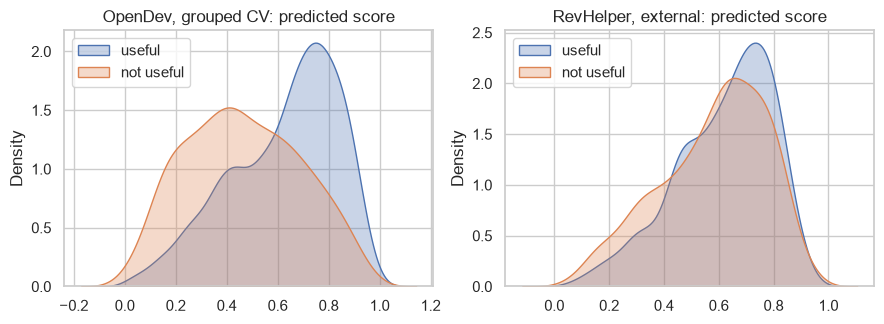

In [10]:
import joblib
joblib.dump({"encoder": FINAL[0], "variant": FINAL[1], "family": FINAL[2], "params": st[FINAL[2]][FINAL[3]], "head": head, "meta_mean": M_od.mean(0), "meta_std": M_od.std(0)}, RESULTS / "substance_scorer.joblib")
json.dump({"final": list(map(str, FINAL)), "params": st[FINAL[2]][FINAL[3]], "rule": rule, "external_auc": ext["AUC"], "cv_auc": cv["AUC"]}, open(RESULTS / "choice.json", "w"), indent=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for a, (n, y, p) in zip(ax, (("OpenDev, grouped CV", od.y, oof_final), ("RevHelper, external", rh.y, p_ext))):
    sns.kdeplot(x=p[y == 1], ax=a, label="useful", fill=True, alpha=.3); sns.kdeplot(x=p[y == 0], ax=a, label="not useful", fill=True, alpha=.3); a.set_title(n + ": predicted score"); a.legend()
fig.tight_layout(); plt.show()

## 8. Reading the results

**Result against the protocol's criteria (fixed before training).**

| Criterion | Value | Verdict |
|---|---|---|
| External AUC, OpenDev to RevHelper (scored once) | 0.557 (95% 0.522 to 0.590) | **not met** (minimum 0.70) |
| Grouped cross-validation AUC within OpenDev | 0.701 (0.672 to 0.729) | minimum met |
| Beats TF-IDF + logistic (paired interval) | -0.012 (-0.042 to +0.015) | **not met** |
| Guard layer: approvals and one-word texts score 0 | all | target met |

**What was chosen.** Of the three frozen encoders, RoBERTa (mean pooling) was best (pooled AUC 0.70), MiniLM and mpnet were about 0.69. Adding length, code and question flags did not help. The rule for a complex head was **not** met: Random Forest on RoBERTa gained +0.004 AUC (interval -0.009 to +0.018), so logistic regression stays as the head. The final configuration is RoBERTa embeddings with logistic regression (C = 32). The reverse direction (train RevHelper, test OpenDev, same configuration) gave 0.489, no signal.

**What it means.** By the protocol's own criteria, the encoder-based scorer is **not shown to work** and does not beat the much simpler TF-IDF baseline. It reproduces about the same weak signal within OpenDev (about 0.70) and does not carry over to the other public set. So the proposal's frozen-encoder-plus-head design is not supported by these data. The likely reasons, which I did not test, are that the two datasets define "useful" differently and that usefulness depends on the code the comment refers to, which the text does not contain. A better encoder would probably not fix that. The optional fine-tuning experiment (protocol step 9) was not run, since a bigger model would not change the label problem.

**Decision.** The rule-based substance score in `cleaning.py` stays as the stand-in for the substance measures. The trained scorer is saved (`results/substance_scorer.joblib`) for comparison and is not recommended for use.